# 51 — Air-to-ground coupling spectra

Extends notebook 50 with:
1. **Frequency-domain H1 transfer function** — per pair, using the same masked Welch
   spectra already computed in nb 50, now plotted as publication figures.
2. **Comparison with AMOS-6** — broadband and spectral coupling from
   Thompson et al. (2026) at BCHH (~1.4 km from SLC-40) provides a
   same-site baseline from a different source type.
3. **Coupling vs time (Phase I window)** — continuous 5-s window ratios through
   the launch, as in supplement figure S5 of paper 1.
4. **Publication-quality figures** — coupling_transfer_functions.pdf,
   coupling_summary.pdf, coupling_vs_time.pdf.

Inputs
------
- SDS archive via `artemis2_config.launch_stream_raw()`
- `artemis2_config.instrument_correct()` and `clip_mask()`
- Station table from `artemis2_config.station_table()`

Outputs (to `cfg.OUT_DIR`)
--------------------------
- `coupling_metrics.csv` — per-pair scalar coupling metrics
- `coupling_transfer_functions.csv` — per-pair H1(f), coherence, phase
- `coupling_transfer_functions.png` — Fig S5 panel: H1 magnitude + coherence grid
- `coupling_summary.png` — Fig main: RMS ratio and band-averaged |H| vs distance
- `coupling_vs_time.png` — Fig S5 panel: coupling ratio through launch


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import get_window

import artemis2_config as cfg

L = cfg.LAUNCHTIME
OUT = cfg.OUT_DIR / "51_coupling_spectra"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.grid': True, 'grid.color': '#dddddd', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False})

SIGNAL = (L, L + 180)          # launch window (first 3 min)
NOISE  = (L - 900, L - 720)    # equal-length pre-launch noise window
BAND   = (1.0, 40.0)           # Hz, common band for time-domain scalar metrics
SEG_S  = 4.0                   # Welch segment length, s
COH_MIN = 0.5                  # coherence threshold for band-averaged |H|
MAXLAG_S = 0.5                 # maximum lag for regression
SUMMARY_BANDS = [(1, 5), (5, 20), (20, 40)]  # Hz

# --- AMOS-6 reference values (Thompson et al. 2026, BCHH, ~1.4 km from SLC-40) ---
# Broadband median seismic/acoustic coupling coefficient (1--40 Hz, 46 events)
AMOS6_COUPLING_UM_S_PA = 2.31      # µm/s/Pa
AMOS6_H1_PEAK_BANDS = [(4, 5), (20, 24)]   # Hz, where H1 peaked at BCHH
AMOS6_H1_PEAK_UM_S_PA = 5.0       # approximate peak magnitude in those bands (µm/s/Pa)
AMOS6_DISTANCE_KM = 1.4            # km (BCHH to SLC-40)

stations = cfg.station_table()

PAIRS = [  # (pressure SEED id, velocity SEED id, pair type label)
    ('1R.B01.00.CD0', '1R.B01.00.CHZ', 'infraBSU-Trillium'),
    ('1R.B03.00.CD0', '1R.B03.00.CHZ', 'infraBSU-Trillium'),
    ('1R.B05.00.CD0', '1R.B05.00.CHZ', 'infraBSU-Trillium'),
    ('1R.B29.00.CD0', '1R.B29.00.CHZ', 'infraBSU-Trillium'),
    ('1R.B01.00.CD0', '1R.B01..DPZ',   'infraBSU-SmartSolo'),
    ('1R.B01..HDI',   '1R.B01..DPZ',   'Gem-SmartSolo'),
    ('1R.B03..HDI',   '1R.B03..DPZ',   'Gem-SmartSolo'),
    ('1R.B07..HDF',   '1R.B07..DPZ',   'Gem-SmartSolo'),
    ('1R.B12..HDF',   '1R.B12..DPZ',   'Gem-SmartSolo'),
    ('1R.B14..HDF',   '1R.B14..DPZ',   'Gem-SmartSolo'),
    ('1R.B20..HDF',   '1R.B20..DPZ',   'Gem-SmartSolo'),
    ('1R.B20S..HDF',  '1R.B20S..DPZ',  'Gem-SmartSolo'),
    ('1R.B20W..HDF',  '1R.B20W..DPZ',  'Gem-SmartSolo'),
    ('1R.B23..HDF',   '1R.B23..DPZ',   'Gem-SmartSolo'),
    ('1R.B24..HDF',   '1R.B24..DPZ',   'Gem-SmartSolo'),
]


## 1. Data

In [2]:
raw = cfg.launch_stream_raw()
clips = cfg.stream_clip_intervals(raw)
st = cfg.instrument_correct(raw)
for tr in st:   # SmartSolo files carry location "--"; normalise to "" so IDs match PAIRS
    if tr.stats.location == '--':
        tr.stats.location = ''
ids = {tr.id for tr in st}
print('missing:', sorted({x for p in PAIRS for x in p[:2]} - ids))

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/ksclib/src/ksclib/data.py:34: UserWarning: SKIPPED unreadable SDS file /Volumes/KSCGTdownld/SDS/2026/1R/B29/DHZ.D/1R.B29.00.DHZ.D.2026.091 (InternalMSEEDParseTimeError)
  warnings.warn(f"SKIPPED unreadable SDS file {path} ({type(exc).__name__})")


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


... (16 outputs left out)

/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


missing: []


In [3]:
def common_pair(p_id, v_id):
    """Pressure and velocity traces at a common rate (lowest of the two), aligned, plus a mask."""
    p, v = st.select(id=p_id)[0].copy(), st.select(id=v_id)[0].copy()
    fs = min(p.stats.sampling_rate, v.stats.sampling_rate)
    for t in (p, v):
        if t.stats.sampling_rate > fs:
            t.filter('lowpass', freq=0.4 * fs, corners=8, zerophase=True)
            t.resample(fs, no_filter=True)
    t0 = max(p.stats.starttime, v.stats.starttime); t1 = min(p.stats.endtime, v.stats.endtime)
    for t in (p, v):
        t.trim(t0, t1, nearest_sample=True)
    n = min(p.stats.npts, v.stats.npts)
    p.data, v.data = p.data[:n].astype(float), v.data[:n].astype(float)
    mask = cfg.clip_mask(p, clips.get(p_id, []))
    return p, v, mask, fs

def masked_welch(x, y, mask, fs, seg_s=SEG_S):
    """Welch auto/cross spectra using only segments that contain no masked sample."""
    n = int(seg_s * fs); step = n // 2
    w = get_window('hann', n); scale = 1.0 / (fs * (w ** 2).sum())
    sxx = syy = sxy = 0; k = 0
    for i in range(0, len(x) - n + 1, step):
        if mask[i:i + n].any():
            continue
        X = np.fft.rfft(w * (x[i:i + n] - x[i:i + n].mean()))
        Y = np.fft.rfft(w * (y[i:i + n] - y[i:i + n].mean()))
        sxx = sxx + np.abs(X) ** 2; syy = syy + np.abs(Y) ** 2; sxy = sxy + np.conj(X) * Y; k += 1
    f = np.fft.rfftfreq(n, 1 / fs)
    if k == 0:
        return f, None
    return f, dict(pxx=scale * sxx / k, pyy=scale * syy / k, pxy=scale * sxy / k, nseg=k)

def window_idx(tr, win):
    t = tr.stats.starttime.timestamp + tr.times()
    return (t >= win[0].timestamp) & (t < win[1].timestamp)

def regression(p, v, fs):
    """k minimising |v - k p(t - lag)|^2 over lags within +-MAXLAG_S; returns k, lag (s), correlation."""
    best = (0, 0, 0)
    m = int(MAXLAG_S * fs)
    for lag in range(-m, m + 1):
        if lag >= 0:
            a, b = p[:len(p) - lag], v[lag:]
        else:
            a, b = p[-lag:], v[:len(v) + lag]
        r = np.corrcoef(a, b)[0, 1]
        if abs(r) > abs(best[2]):
            best = (np.dot(a, b) / np.dot(a, a), lag / fs, r)
    return best

## 2. Coupling coefficients and transfer functions

In [4]:
rows, tf_rows, tfs = [], [], {}
for p_id, v_id, kind in PAIRS:
    if p_id not in ids or v_id not in ids:
        continue
    p, v, mask, fs = common_pair(p_id, v_id)
    sta = p.stats.station
    pb, vb = p.copy(), v.copy()
    for t in (pb, vb):
        t.filter('bandpass', freqmin=BAND[0], freqmax=BAND[1], corners=4, zerophase=True)
    sig = window_idx(p, SIGNAL) & ~mask
    noi = window_idx(p, NOISE)
    k, lag, r = regression(pb.data[sig], vb.data[sig], fs)
    row = dict(pair=f"{p_id.replace('1R.', '')} / {v_id.replace('1R.', '')}", pressure=p_id, velocity=v_id,
               kind=kind, station=sta, distance_km=stations.distance_km.get(sta, np.nan), fs=fs,
               masked_s=mask[window_idx(p, SIGNAL)].sum() / fs,
               peak_p_Pa=np.abs(pb.data[sig]).max(), peak_v_mps=np.abs(vb.data[sig]).max(),
               k_peak_um_s_Pa=1e6 * np.abs(vb.data[sig]).max() / np.abs(pb.data[sig]).max(),
               k_rms_um_s_Pa=1e6 * vb.data[sig].std() / pb.data[sig].std(),
               k_regression_um_s_Pa=1e6 * k, lag_s=lag, corr=r,
               noise_k_rms_um_s_Pa=1e6 * vb.data[noi].std() / pb.data[noi].std())
    f, sp = masked_welch(p.data[window_idx(p, SIGNAL)], v.data[window_idx(p, SIGNAL)],
                         mask[window_idx(p, SIGNAL)], fs)
    if sp is not None:
        H = sp['pxy'] / sp['pxx']
        coh = np.abs(sp['pxy']) ** 2 / (sp['pxx'] * sp['pyy'])
        tfs[row['pair']] = dict(f=f, H=H, coh=coh, kind=kind, dist=row['distance_km'])
        row['n_segments'] = sp['nseg']
        for lo, hi in SUMMARY_BANDS:
            m = (f >= lo) & (f < hi) & (coh >= COH_MIN)
            row[f'H_{lo}-{hi}Hz_um_s_Pa'] = 1e6 * np.median(np.abs(H[m])) if m.any() else np.nan
            row[f'coh_{lo}-{hi}Hz'] = np.median(coh[(f >= lo) & (f < hi)])
            row[f'phase_{lo}-{hi}Hz_deg'] = np.degrees(np.angle(np.median(H[m] / np.abs(H[m])))) if m.any() else np.nan
        for fi, h, c in zip(f, H, coh):
            if 0.5 <= fi <= 0.45 * fs:
                tf_rows.append(dict(pair=row['pair'], f_hz=fi, H_abs_um_s_Pa=1e6 * abs(h),
                                    phase_deg=np.degrees(np.angle(h)), coherence=c))
    rows.append(row)

coup = pd.DataFrame(rows)
coup.to_csv(OUT / 'coupling_metrics.csv', index=False)
pd.DataFrame(tf_rows).to_csv(OUT / 'coupling_transfer_functions.csv', index=False)
cols = ['pair', 'kind', 'distance_km', 'masked_s', 'k_rms_um_s_Pa', 'k_peak_um_s_Pa', 'k_regression_um_s_Pa',
        'corr', 'lag_s', 'noise_k_rms_um_s_Pa'] + [c for c in coup.columns if c.startswith(('H_', 'coh_', 'phase_'))]
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.width', 250):
    display(coup[cols].sort_values('distance_km'))

,pair,kind,distance_km,masked_s,k_rms_um_s_Pa,k_peak_um_s_Pa,k_regression_um_s_Pa,corr,lag_s,noise_k_rms_um_s_Pa,H_1-5Hz_um_s_Pa,coh_1-5Hz,phase_1-5Hz_deg,H_5-20Hz_um_s_Pa,coh_5-20Hz,phase_5-20Hz_deg,H_20-40Hz_um_s_Pa,coh_20-40Hz,phase_20-40Hz_deg
9,B14..HDF / B14..DPZ,Gem-SmartSolo,0.739,28.6,4.54,6.88,1.27,0.281,-0.01,37.2,0.721,0.198,48.6,2.15,0.714,70.9,8.24,0.413,-47.7
0,B01.00.CD0 / B01.00.CHZ,infraBSU-Trillium,1.53,0,7.51,9.02,-2.64,-0.351,0.004,60.9,0.579,0.196,-92.1,5.05,0.3,-170,7.05,0.319,134
4,B01.00.CD0 / B01..DPZ,infraBSU-SmartSolo,1.53,0,7.54,8.94,2.66,0.352,0.004,61.3,NaN,0.19,NaN,5.34,0.317,13.3,7.12,0.305,-60.2
5,B01..HDI / B01..DPZ,Gem-SmartSolo,1.53,22.6,5.15,9.55,1.45,0.281,-0.01,63.7,0.592,0.162,75.6,3.77,0.27,81.5,5.54,0.507,33.9
1,B03.00.CD0 / B03.00.CHZ,infraBSU-Trillium,1.75,0,54.7,110,5.04,0.0921,0.362,1.54,NaN,0.0357,NaN,NaN,0.103,NaN,NaN,0.0942,NaN
6,B03..HDI / B03..DPZ,Gem-SmartSolo,1.75,14.4,6.86,6.83,-1.44,-0.211,0.12,15.9,1.3,0.348,80.6,2.82,0.163,62.6,3.53,0.567,29.2
8,B12..HDF / B12..DPZ,Gem-SmartSolo,2.65,13.6,9.5,10.6,3.18,0.334,0,2.22,NaN,0.305,NaN,11.5,0.412,17.6,6.43,0.595,55.1
2,B05.00.CD0 / B05.00.CHZ,infraBSU-Trillium,2.76,0,3.2,4.69,0.775,0.242,0.044,10.9,NaN,0.0519,NaN,1.63,0.26,109,2.38,0.642,-109
7,B07..HDF / B07..DPZ,Gem-SmartSolo,3.42,0,6,5.64,1.41,0.236,0.02,54,NaN,0.0966,NaN,2.02,0.356,-123,1.52,0.377,137
14,B24..HDF / B24..DPZ,Gem-SmartSolo,5.53,0,7.48,5.81,2.15,0.287,0,12.4,NaN,0.255,NaN,5.31,0.504,-31.4,5.98,0.496,39.6


### Polarity

For local loading of the ground by the air wave, positive (compressive) pressure pushes the surface
down, so with "up = positive" the regression coefficient should be **negative**.

In [5]:
for kind, g in coup.groupby('kind'):
    print(f"{kind:20s} regression sign: {', '.join(f'{s}:{np.sign(k):+.0f}' for s, k in zip(g.station, g.k_regression_um_s_Pa))}")

Gem-SmartSolo        regression sign: B01:+1, B03:-1, B07:+1, B12:+1, B14:+1, B20:+1, B20S:+1, B20W:+1, B23:+1, B24:+1
infraBSU-SmartSolo   regression sign: B01:+1
infraBSU-Trillium    regression sign: B01:-1, B03:+1, B05:+1, B29:-1


## 3. Publication figure: H1 transfer function grid

One panel per pair, sorted by distance. Each panel shows:
- H1 magnitude (µm s⁻¹ Pa⁻¹) in grey where coherence < `COH_MIN`, coloured where ≥ `COH_MIN`
- Coherence below the magnitude
- Vertical bands at the AMOS-6 H1 peak frequencies (4–5 Hz, 20–24 Hz) for reference


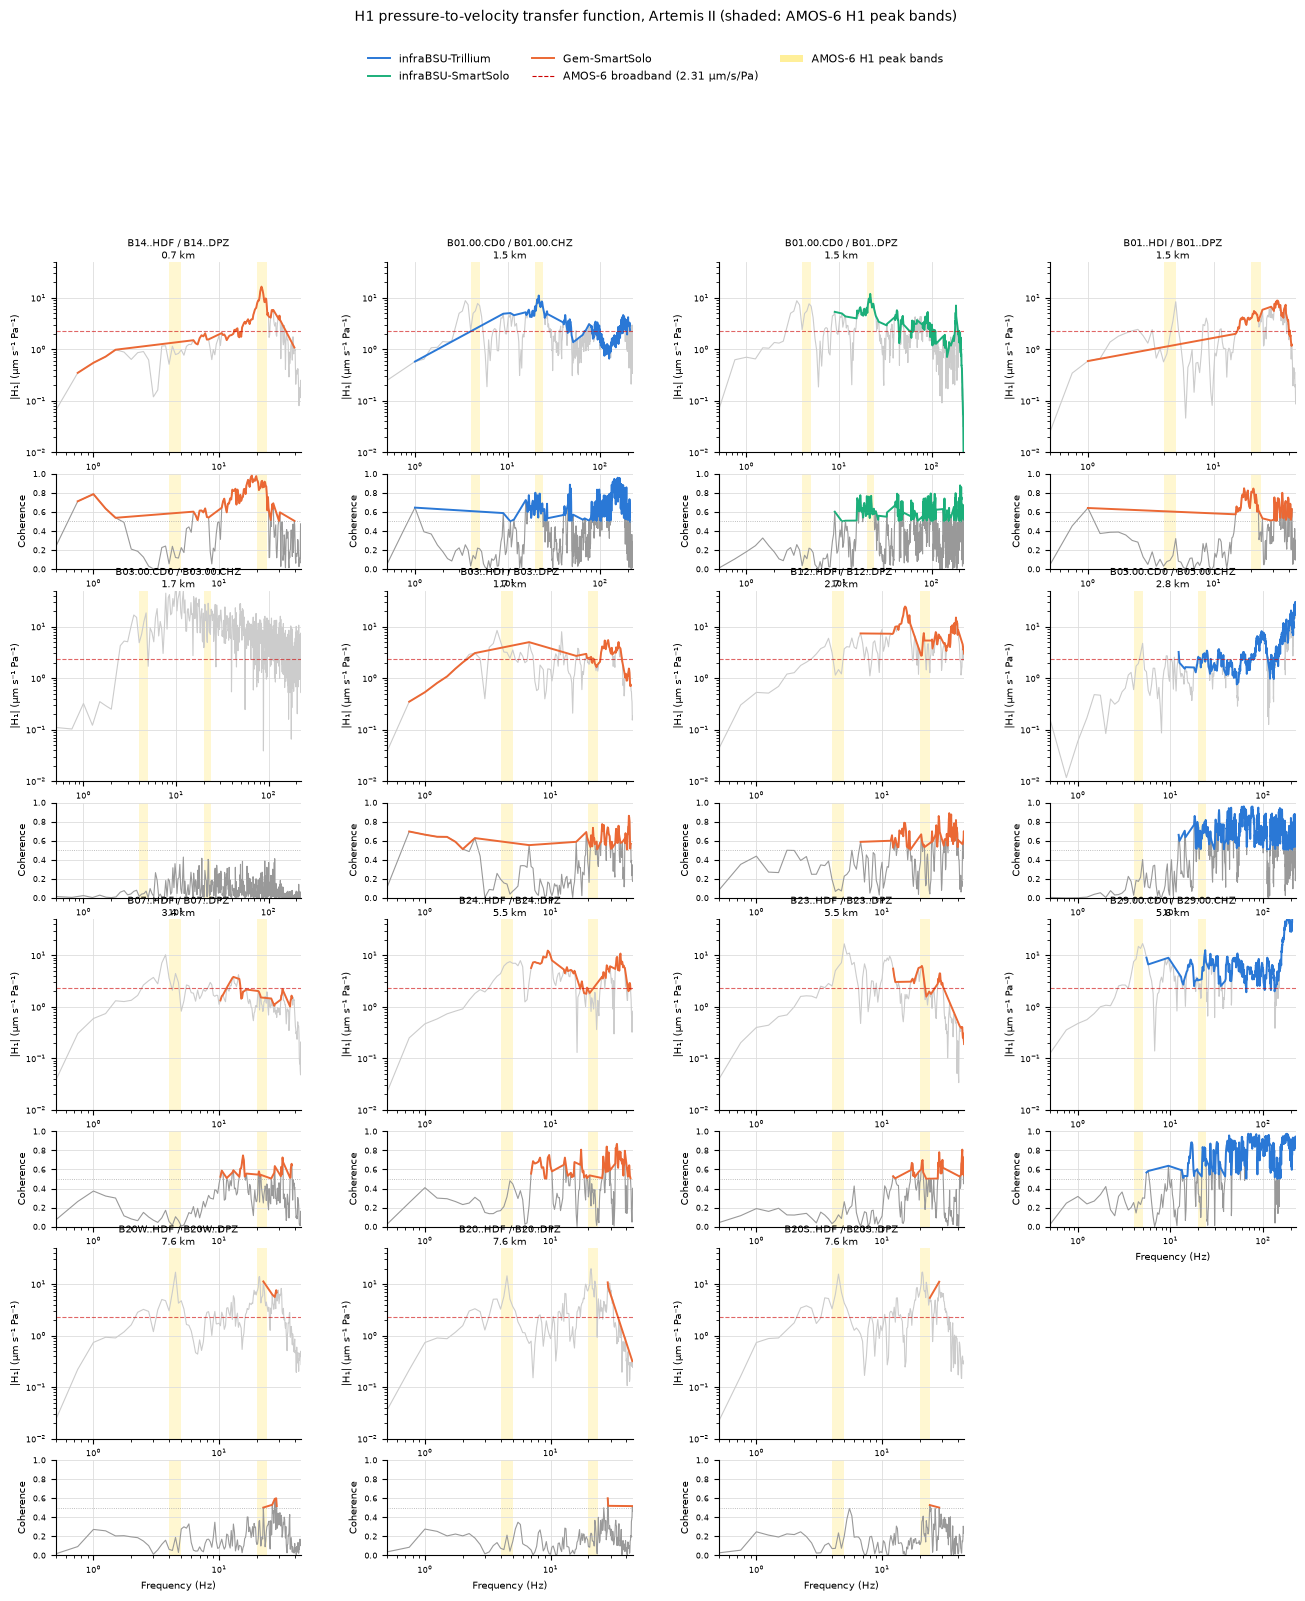

Saved coupling_transfer_functions.png


In [6]:
pairs_sorted = coup.sort_values('distance_km').pair.tolist()
pairs_sorted = [p for p in pairs_sorted if p in tfs]

MARK_COLORS = {
    'infraBSU-Trillium': '#2a78d6',
    'infraBSU-SmartSolo': '#1baf7a',
    'Gem-SmartSolo': '#eb6834',
}

ncol = 4
nrow = int(np.ceil(len(pairs_sorted) / ncol))
fig = plt.figure(figsize=(16, 4.2 * nrow))
gs = fig.add_gridspec(2 * nrow, ncol, height_ratios=[2, 1] * nrow, hspace=0.15, wspace=0.35)

for i, pair in enumerate(pairs_sorted):
    r, c = divmod(i, ncol)
    a1 = fig.add_subplot(gs[2 * r, c])
    a2 = fig.add_subplot(gs[2 * r + 1, c], sharex=a1)
    d = tfs[pair]
    f, H, coh = d['f'], d['H'], d['coh']
    fs_pair = coup.set_index('pair').loc[pair, 'fs']
    dist = coup.set_index('pair').loc[pair, 'distance_km']
    col = MARK_COLORS.get(d['kind'], '#888888')
    m = (f >= 0.5) & (f <= 0.45 * fs_pair)
    good = m & (coh >= COH_MIN)

    # Shade AMOS-6 H1 peak bands
    for lo, hi in AMOS6_H1_PEAK_BANDS:
        a1.axvspan(lo, hi, color='gold', alpha=0.18, lw=0, zorder=0)
        a2.axvspan(lo, hi, color='gold', alpha=0.18, lw=0, zorder=0)

    a1.loglog(f[m], 1e6 * np.abs(H[m]), color='#cccccc', lw=0.8)
    if good.any():
        a1.loglog(f[good], 1e6 * np.abs(H[good]), color=col, lw=1.4)
    # AMOS-6 reference line
    a1.axhline(AMOS6_COUPLING_UM_S_PA, color='#cc0000', lw=0.8, ls='--', alpha=0.6)

    a2.semilogx(f[m], coh[m], color='#999999', lw=0.8)
    if good.any():
        a2.semilogx(f[good], coh[good], color=col, lw=1.4)
    a2.axhline(COH_MIN, color='#aaaaaa', lw=0.6, ls=':')

    sta = pair.split('.')[0].split('/')[0].strip()
    a1.set_title(f"{pair}\n{dist:.1f} km", fontsize=7, pad=2)
    a1.set_ylabel('|H₁| (µm s⁻¹ Pa⁻¹)', fontsize=7)
    a2.set_ylabel('Coherence', fontsize=7)
    a2.set_xlabel('Frequency (Hz)', fontsize=7)
    a1.set_ylim(1e-2, 50)
    a2.set_ylim(0, 1)
    for ax in (a1, a2):
        ax.tick_params(labelsize=6)
        ax.set_xlim(0.5, 0.45 * fs_pair)

# Legend
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], color=c, lw=1.4, label=k)
           for k, c in MARK_COLORS.items()]
handles.append(Line2D([0], [0], color='#cc0000', lw=0.8, ls='--',
                       label=f'AMOS-6 broadband ({AMOS6_COUPLING_UM_S_PA} µm/s/Pa)'))
handles.append(plt.Rectangle((0, 0), 1, 1, fc='gold', alpha=0.4,
                               label='AMOS-6 H1 peak bands'))
fig.legend(handles=handles, loc='upper center', ncol=3, fontsize=8,
           bbox_to_anchor=(0.5, 1.01), frameon=False)
fig.suptitle('H1 pressure-to-velocity transfer function, Artemis II (shaded: AMOS-6 H1 peak bands)',
             fontsize=10, y=1.03)
fig.savefig(OUT / 'coupling_transfer_functions.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved coupling_transfer_functions.png")


## 4. Publication figure: coupling summary vs distance

Left panel: RMS coupling ratio (1–40 Hz) by site and instrument pair.  
Right panel: coherent |H₁| in three frequency bands.  
Red dashed line marks the AMOS-6 broadband median at 1.4 km.


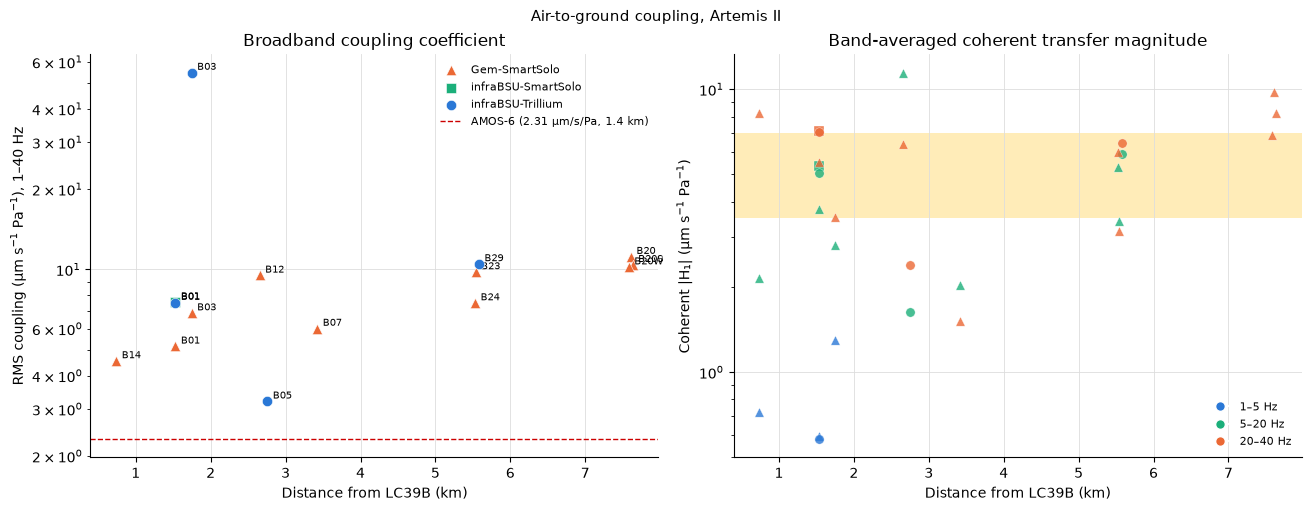

Saved coupling_summary.png


In [7]:
MARK = {
    'infraBSU-Trillium': ('o', '#2a78d6'),
    'infraBSU-SmartSolo': ('s', '#1baf7a'),
    'Gem-SmartSolo':      ('^', '#eb6834'),
}
band_cols = [f'H_{lo}-{hi}Hz_um_s_Pa' for lo, hi in SUMMARY_BANDS]
band_labels = [f'{lo}–{hi} Hz' for lo, hi in SUMMARY_BANDS]
band_colors = ['#2a78d6', '#1baf7a', '#eb6834']

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

ax0, ax1 = axes

for kind, g in coup.groupby('kind'):
    mk, col = MARK[kind]
    ax0.scatter(g.distance_km, g.k_rms_um_s_Pa, marker=mk, color=col,
                s=55, label=kind, zorder=3, edgecolors='white', linewidths=0.4)
    for _, row in g.iterrows():
        ax0.annotate(row.station, (row.distance_km, row.k_rms_um_s_Pa),
                     fontsize=7, xytext=(4, 2), textcoords='offset points')

# AMOS-6 reference
ax0.axhline(AMOS6_COUPLING_UM_S_PA, color='#cc0000', lw=1.0, ls='--',
            label=f'AMOS-6 ({AMOS6_COUPLING_UM_S_PA} µm/s/Pa, 1.4 km)')
ax0.set(yscale='log', xlabel='Distance from LC39B (km)',
        ylabel='RMS coupling (µm s$^{-1}$ Pa$^{-1}$), 1–40 Hz',
        title='Broadband coupling coefficient')
ax0.legend(frameon=False, fontsize=8)

for col_name, label, color in zip(band_cols, band_labels, band_colors):
    vals = coup.dropna(subset=[col_name])
    if vals.empty:
        continue
    for kind, g in vals.groupby('kind'):
        mk = MARK[kind][0]
        ax1.scatter(g.distance_km, g[col_name], marker=mk, color=color,
                    s=45, alpha=0.8, zorder=3, edgecolors='white', linewidths=0.3)

# AMOS-6 H1 peak reference bands
for (lo, hi), band_color in zip(AMOS6_H1_PEAK_BANDS, ['gold', 'orange']):
    ax1.axhspan(AMOS6_H1_PEAK_UM_S_PA * 0.7, AMOS6_H1_PEAK_UM_S_PA * 1.4,
                color=band_color, alpha=0.15, lw=0)

ax1.set(yscale='log', xlabel='Distance from LC39B (km)',
        ylabel='Coherent |H₁| (µm s$^{-1}$ Pa$^{-1}$)',
        title='Band-averaged coherent transfer magnitude')

# Manual legend for bands
from matplotlib.lines import Line2D
band_handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c,
                        markersize=7, label=lbl)
                for c, lbl in zip(band_colors, band_labels)]
ax1.legend(handles=band_handles, frameon=False, fontsize=8)

fig.suptitle('Air-to-ground coupling, Artemis II', fontsize=11)
fig.savefig(OUT / 'coupling_summary.png', dpi=200, bbox_inches='tight')
plt.show()
print("Saved coupling_summary.png")


## 5. Coupling through time (supplement figure)

5-second RMS coupling ratio through the launch for each pair, masked at Gem overflow.  
B20-group ratios are elevated before the air wave arrives because pad-coupled seismic
energy arrives earlier than the acoustic wave.


In [8]:
WIN = 5.0   # s
trows = []
for p_id, v_id, kind in PAIRS:
    if p_id not in ids or v_id not in ids:
        continue
    p, v, mask, fs = common_pair(p_id, v_id)
    for t in (p, v):
        t.filter('bandpass', freqmin=BAND[0], freqmax=BAND[1], corners=4, zerophase=True)
    for t0_off in np.arange(0, 180, WIN):
        idx = window_idx(p, (L + t0_off, L + t0_off + WIN))
        if mask[idx].any():
            continue
        pv = p.data[idx]; vv = v.data[idx]
        ps = pv.std(); vs = vv.std()
        if ps < 1e-9:
            continue
        sta = p.stats.station
        trows.append(dict(pair=f"{p_id.replace('1R.', '')} / {v_id.replace('1R.', '')}",
                          station=sta, kind=kind,
                          distance_km=stations.distance_km.get(sta, np.nan),
                          t_mid=t0_off + WIN / 2,
                          k_rms_um_s_Pa=1e6 * vs / ps))

ktime = pd.DataFrame(trows)
ktime.to_csv(OUT / 'coupling_vs_time.csv', index=False)
print(f"Computed {len(ktime)} time windows across {ktime.pair.nunique()} pairs")


Computed 519 time windows across 15 pairs


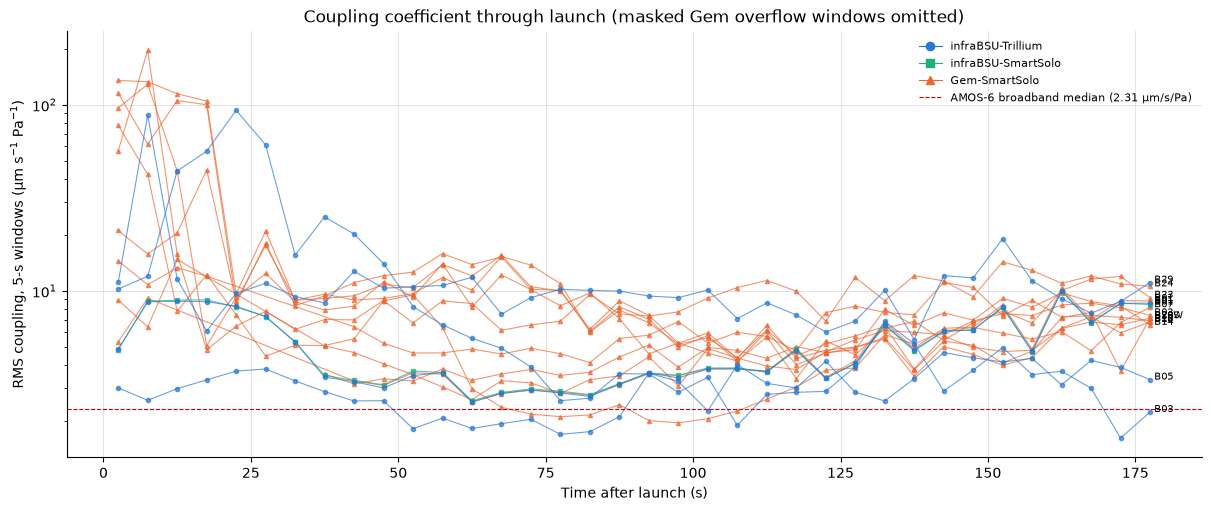

Saved coupling_vs_time.png


In [9]:
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
MARK = {
    'infraBSU-Trillium': ('o', '#2a78d6'),
    'infraBSU-SmartSolo': ('s', '#1baf7a'),
    'Gem-SmartSolo':      ('^', '#eb6834'),
}
for kind, g in ktime.groupby('kind'):
    mk, col = MARK[kind]
    for pair, h in g.groupby('pair'):
        ax.plot(h.t_mid, h.k_rms_um_s_Pa, marker=mk, ms=3, lw=0.8,
                color=col, alpha=0.7)
        ax.annotate(pair.split('.')[0], (h.t_mid.iloc[-1], h.k_rms_um_s_Pa.iloc[-1]),
                    fontsize=7, xytext=(3, 0), textcoords='offset points')

ax.axhline(AMOS6_COUPLING_UM_S_PA, color='#cc0000', lw=0.8, ls='--',
           label=f'AMOS-6 broadband median ({AMOS6_COUPLING_UM_S_PA} µm/s/Pa)')
ax.set(yscale='log', xlabel='Time after launch (s)',
       ylabel='RMS coupling, 5-s windows (µm s$^{-1}$ Pa$^{-1}$)',
       title='Coupling coefficient through launch (masked Gem overflow windows omitted)')
ax.legend(frameon=False, fontsize=8)

from matplotlib.lines import Line2D
kind_handles = [Line2D([0], [0], marker=MARK[k][0], color=MARK[k][1],
                        markersize=6, lw=0.8, label=k)
                for k in MARK]
existing = ax.get_legend()
all_handles = kind_handles + existing.legend_handles
ax.legend(handles=all_handles, frameon=False, fontsize=8)

fig.savefig(OUT / 'coupling_vs_time.png', dpi=200)
plt.show()
print("Saved coupling_vs_time.png")


## 6. Comparison with AMOS-6

Summary of how Artemis II coupling compares with the 2016 Falcon 9 AMOS-6 baseline
at the same site (Thompson et al., 2026).

Key points:
- AMOS-6 broadband median: **2.31 µm/s/Pa** at BCHH (~1.4 km from SLC-40)
- AMOS-6 H1 peaks: **4–5 Hz and 20–24 Hz** at BCHH
- Artemis II uses a range of distances (0.7–7.6 km) and sensor types
- Different source: continuous SLS exhaust vs impulsive Falcon 9 explosion sequence
- Same site geology (shallow carbonate platform sediments, coastal Florida)


In [10]:
# Comparison table: Artemis II broadband RMS vs AMOS-6 reference
comparison = coup[['pair', 'kind', 'distance_km', 'k_rms_um_s_Pa',
                   'H_1-5Hz_um_s_Pa', 'H_5-20Hz_um_s_Pa', 'H_20-40Hz_um_s_Pa']].copy()
comparison = comparison.sort_values('distance_km')
comparison['amos6_ref_um_s_Pa'] = AMOS6_COUPLING_UM_S_PA
comparison['ratio_to_amos6'] = comparison['k_rms_um_s_Pa'] / AMOS6_COUPLING_UM_S_PA

print("Artemis II coupling vs AMOS-6 reference (2.31 µm/s/Pa):")
print()
with pd.option_context('display.float_format', '{:.2g}'.format, 'display.width', 180):
    print(comparison.to_string(index=False))

# Save for paper
comparison.to_csv(OUT / 'coupling_amos6_comparison.csv', index=False)
print()
print(f"Median Artemis II RMS coupling: {coup.k_rms_um_s_Pa.median():.2f} µm/s/Pa")
print(f"Range: {coup.k_rms_um_s_Pa.min():.2f} – {coup.k_rms_um_s_Pa.max():.2f} µm/s/Pa")
print(f"AMOS-6 reference: {AMOS6_COUPLING_UM_S_PA:.2f} µm/s/Pa")


Artemis II coupling vs AMOS-6 reference (2.31 µm/s/Pa):

                   pair               kind  distance_km  k_rms_um_s_Pa  H_1-5Hz_um_s_Pa  H_5-20Hz_um_s_Pa  H_20-40Hz_um_s_Pa  amos6_ref_um_s_Pa  ratio_to_amos6
    B14..HDF / B14..DPZ      Gem-SmartSolo         0.74            4.5             0.72               2.2                8.2                2.3               2
B01.00.CD0 / B01.00.CHZ  infraBSU-Trillium          1.5            7.5             0.58               5.1                7.1                2.3             3.2
  B01.00.CD0 / B01..DPZ infraBSU-SmartSolo          1.5            7.5              NaN               5.3                7.1                2.3             3.3
    B01..HDI / B01..DPZ      Gem-SmartSolo          1.5            5.1             0.59               3.8                5.5                2.3             2.2
B03.00.CD0 / B03.00.CHZ  infraBSU-Trillium          1.7             55              NaN               NaN                NaN                2.3

## 7. Output summary


In [11]:
outputs = [
    'coupling_metrics.csv',
    'coupling_transfer_functions.csv',
    'coupling_transfer_functions.png',
    'coupling_summary.png',
    'coupling_vs_time.csv',
    'coupling_vs_time.png',
    'coupling_amos6_comparison.csv',
]
print("Outputs written to:", OUT)
for f in outputs:
    p = OUT / f
    status = f"{p.stat().st_size / 1024:.1f} kB" if p.exists() else "MISSING"
    print(f"  {f}: {status}")


Outputs written to: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/51_coupling_spectra
  coupling_metrics.csv: 5.7 kB
  coupling_transfer_functions.csv: 523.4 kB
  coupling_transfer_functions.png: 926.9 kB
  coupling_summary.png: 156.4 kB
  coupling_vs_time.csv: 42.3 kB
  coupling_vs_time.png: 504.6 kB
  coupling_amos6_comparison.csv: 2.1 kB
